### **K-means vs Random Initialization**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src.distributions import LCG, uniform, gaussian
from src.gmm import GMM
from src.kmeans import KMeans

### **Experiment-only GMM Copy**


In [2]:
class GMM:
    def __init__(self, K=3, reg=1e-6, max_iter=100, tol=1e-6,
                 init="kmeans", seed=42):
        self.K = K
        self.reg = reg
        self.max_iter = max_iter
        self.tol = tol
        self.init = init
        self.seed = seed
        self.weights = None
        self.means = None
        self.covariances = None
        self.log_likelihoods = []

    def component_scores(self, X):
        n, d = X.shape
        scores = np.zeros((n, self.K))

        for k in range(self.K):
            difference = X - self.means[k]
            eigenvalues = np.linalg.eigvalsh(self.covariances[k])
            if np.any(eigenvalues <= 0):
                raise ValueError("Covariance must be positive definite. Try a larger reg.")
            # Log determinant = sum of the logs of the eigenvalues.
            log_det = np.log(eigenvalues).sum()
            inverse_covariance = np.linalg.inv(self.covariances[k])
            # Quadratic term: (x - mean).T @ inverse_covariance @ (x - mean)
            d_squared = np.sum((difference @ inverse_covariance) * difference, axis=1)
            scores[:, k] = np.log(self.weights[k]) - 0.5 * (
                d * np.log(2 * np.pi) + log_det + d_squared
            )

        return scores

    def score_samples(self, X):
        # log of the mixture density, calculated without tiny exponentials
        scores = self.component_scores(X)
        largest = scores.max(axis=1)
        return largest + np.log(np.exp(scores - largest[:, None]).sum(axis=1))

    def fit(self, X):
        n, d = X.shape
        self.log_likelihoods = []

        if self.init == "kmeans":
            model = KMeans(K=self.K)
            model.fit(X)
            labels = model.predict(X)

            self.means = model.centers.copy()
            self.weights = np.zeros(self.K)
            self.covariances = np.zeros((self.K, d, d))

            for k in range(self.K):
                points = X[labels == k]
                if len(points) == 0:
                    raise ValueError("K-means produced an empty component. Try another K.")
                difference = points - self.means[k]
                self.weights[k] = len(points) / n
                self.covariances[k] = difference.T @ difference / len(points)
                self.covariances[k] += self.reg * np.eye(d)
        elif self.init == "random":
            rng = np.random.default_rng(self.seed)
            indices = rng.choice(n, size=self.K, replace=False)
            self.means = X[indices].copy()
            self.weights = np.full(self.K, 1.0 / self.K)
            difference = X - X.mean(axis=0)
            covariance = difference.T @ difference / n
            covariance += self.reg * np.eye(d)
            self.covariances = np.array([covariance.copy() for _ in range(self.K)])
        else:
            raise ValueError("init must be 'kmeans' or 'random'.")

        for _ in range(self.max_iter):
            # E-step: soft membership of each point in each component
            scores = self.component_scores(X)
            scores -= scores.max(axis=1, keepdims=True)
            responsibilities = np.exp(scores)
            responsibilities /= responsibilities.sum(axis=1, keepdims=True)

            # M-step: update weights, means, and covariances
            counts = responsibilities.sum(axis=0)
            if np.any(counts < 1e-10):
                raise ValueError("A component has no effective points. Try a smaller K.")
            self.weights = counts / n
            self.means = responsibilities.T @ X / counts[:, None]

            for k in range(self.K):
                difference = X - self.means[k]
                weighted_difference = responsibilities[:, k, None] * difference
                self.covariances[k] = difference.T @ weighted_difference / counts[k]
                self.covariances[k] += self.reg * np.eye(d)

            log_likelihood = self.score_samples(X).mean()
            self.log_likelihoods.append(log_likelihood)
            if len(self.log_likelihoods) > 1:
                change = self.log_likelihoods[-1] - self.log_likelihoods[-2]
                if abs(change) < self.tol:
                    break

        return self


In [3]:
n = 5000
K = 3
weights = np.array([0.5, 0.3, 0.2])

means = np.array([[-1.0, -3.5], [0.0, 0.0], [1.0, 3.5]])
means_2 = means + np.array([7.0, 0.0])
class_means = [means, means_2]

covariances = [
    np.array([[1.0, 0.6], [0.6, 1.0]]),  # bottom: full
    np.eye(2),                           # middle: isotropic
    np.diag([1.5, 0.5])                  # top: diagonal
]

covariances_2 = [
    np.array([[1.0, -0.6], [-0.6, 1.0]]),
    np.eye(2),
    np.array([[1.5, -0.5], [-0.5, 0.5]])
]
class_covariances = [covariances, covariances_2]
covariance_names = [
    ["Full (+tilt)", "Isotropic", "Diagonal"],
    ["Full (-tilt)", "Isotropic", "Full (-tilt)"]
]

In [4]:
# GMM data generation - 2 GMMs each has 3 gaussian components.

class_samples = []
class_component_labels = []

for class_index in range(2):
    rng = LCG(42 + class_index)
    labels = np.zeros(n, dtype=int)
    for i in range(n):
        u = uniform(0, 1, 1, rng)[0]
        if u < weights[0]:
            labels[i] = 0
        elif u < weights[0] + weights[1]:
            labels[i] = 1
        else:
            labels[i] = 2

    X = np.zeros((n, 2))

    for k in range(K):
        selected = labels == k
        component_n = np.sum(selected)

        eigenvalues, eigenvectors = np.linalg.eigh(class_covariances[class_index][k])
        cov_sqrt = eigenvectors @ np.diag(np.sqrt(eigenvalues)) @ eigenvectors.T

        standard_samples = np.column_stack((
            gaussian(0, 1, component_n, rng),
            gaussian(0, 1, component_n, rng)
        ))
        X[selected] = standard_samples @ cov_sqrt.T + class_means[class_index][k]

    class_samples.append(X)
    class_component_labels.append(labels)

print([sample.shape for sample in class_samples])
print([labels.shape for labels in class_component_labels])

[(5000, 2), (5000, 2)]
[(5000,), (5000,)]


In [5]:
# train and test split - 80% train and 20% test

train_class_samples = []
test_class_samples = []

rng = np.random.default_rng(44)
train_end = int(0.8 * n)

for samples in class_samples:
    shuffled = samples[rng.permutation(n)]
    train_class_samples.append(shuffled[:train_end])
    test_class_samples.append(shuffled[train_end:])

### **Compare Average Training Log-Likelihood**


In [6]:
seed = 42
results = []

for samples in train_class_samples:
    runs = []
    model = GMM(K=3, max_iter=300, tol=1e-6)
    model.fit(samples)
    runs.append(("K-means", model))

    model = GMM(K=3, max_iter=300, tol=1e-6, init="random", seed=seed)
    model.fit(samples)
    runs.append(("Random (seed 42)", model))

    results.append(runs)

for class_index, runs in enumerate(results):
    print(f"Class {class_index + 1}")
    for name, model in runs:
        print(f"{name:12s} iterations={len(model.log_likelihoods):3d} "
              f"final average log-likelihood={model.log_likelihoods[-1]:.8f}")
        if len(model.log_likelihoods) == model.max_iter:
            print("  Iteration limit reached.")
    print()


Class 1
K-means      iterations= 29 final average log-likelihood=-3.59340419
Random (seed 42) iterations= 48 final average log-likelihood=-3.59340431

Class 2
K-means      iterations= 10 final average log-likelihood=-3.63638859
Random (seed 42) iterations= 29 final average log-likelihood=-3.63638826



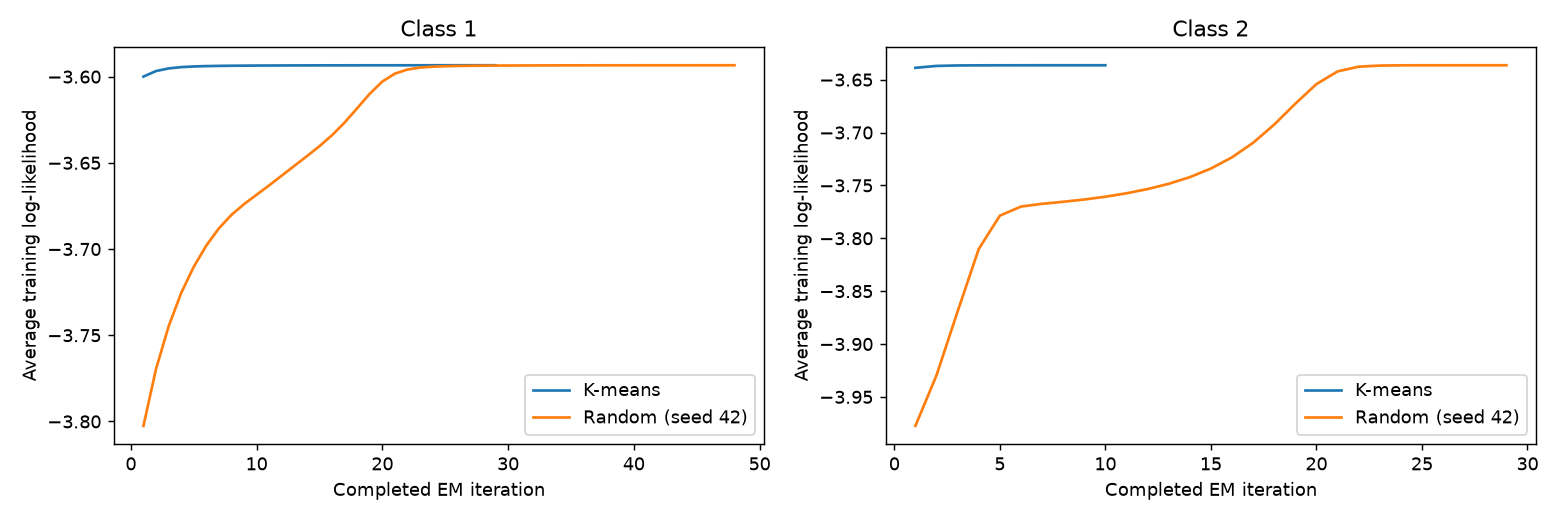

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for class_index, runs in enumerate(results):
    for name, model in runs:
        iterations = np.arange(1, len(model.log_likelihoods) + 1)
        axes[class_index].plot(iterations, model.log_likelihoods, label=name)
    axes[class_index].set_title(f"Class {class_index + 1}")
    axes[class_index].set_xlabel("Completed EM iteration")
    axes[class_index].set_ylabel("Average training log-likelihood")
    axes[class_index].legend()
fig.tight_layout()
plt.show()
